In [7]:
# Import the required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.decomposition import PCA

In [8]:
columns = [
    "Pregnancies", "Glucose", "BloodPressure",
    "SkinThickness", "Insulin", "BMI",
    "DiabetesPedigreeFunction", "Age", "Outcome"
]

df = pd.read_csv("pima-indians-diabetes.csv", header=None)
df.columns = columns

print(df.head())
print("Dataset shape:", df.shape)

   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  
Dataset shape: (768, 9)


In [9]:
X = df.drop("Outcome", axis=1)
y = df["Outcome"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (768, 8)
Target shape: (768,)


In [10]:
print("Missing values:\n", df.isnull().sum())

medical_columns = [
    "Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"
]

print("Zero values in medical measurements:\n",
      (df[medical_columns] == 0).sum())

Missing values:
 Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64
Zero values in medical measurements:
 Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64


In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 614
Testing samples: 154


In [12]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed.")

Feature scaling completed.


In [14]:
k_values = range(1, 21)
accuracies = []

for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train_scaled, y_train)

    y_pred = model.predict(X_test_scaled)
    accuracy = accuracy_score(y_test, y_pred)

    accuracies.append(accuracy)
    print("K =", k, "Accuracy =", round(accuracy, 4))

K = 1 Accuracy = 0.7078
K = 2 Accuracy = 0.7273
K = 3 Accuracy = 0.6948
K = 4 Accuracy = 0.7078
K = 5 Accuracy = 0.7013
K = 6 Accuracy = 0.7403
K = 7 Accuracy = 0.7468
K = 8 Accuracy = 0.7338
K = 9 Accuracy = 0.7338
K = 10 Accuracy = 0.7338
K = 11 Accuracy = 0.7208
K = 12 Accuracy = 0.7727
K = 13 Accuracy = 0.7597
K = 14 Accuracy = 0.7597
K = 15 Accuracy = 0.7532
K = 16 Accuracy = 0.7338
K = 17 Accuracy = 0.7468
K = 18 Accuracy = 0.7273
K = 19 Accuracy = 0.7597
K = 20 Accuracy = 0.7338


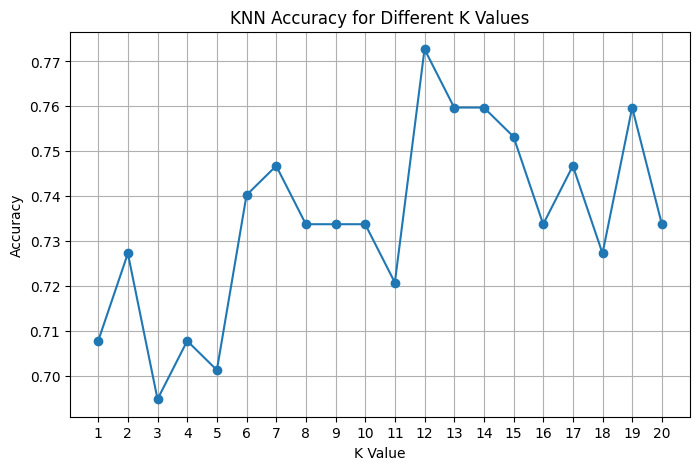

In [15]:
plt.figure(figsize=(8, 5))

plt.plot(k_values, accuracies, marker="o")
plt.xlabel("K Value")
plt.ylabel("Accuracy")
plt.title("KNN Accuracy for Different K Values")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

In [16]:
best_index = np.argmax(accuracies)
best_k = list(k_values)[best_index]
best_accuracy = accuracies[best_index]

print("Best K value:", best_k)
print("Highest test accuracy:", round(best_accuracy, 4))

Best K value: 12
Highest test accuracy: 0.7727


In [17]:
pca = PCA(n_components=2)

X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

print("PCA training shape:", X_train_pca.shape)
print("PCA testing shape:", X_test_pca.shape)

PCA training shape: (614, 2)
PCA testing shape: (154, 2)


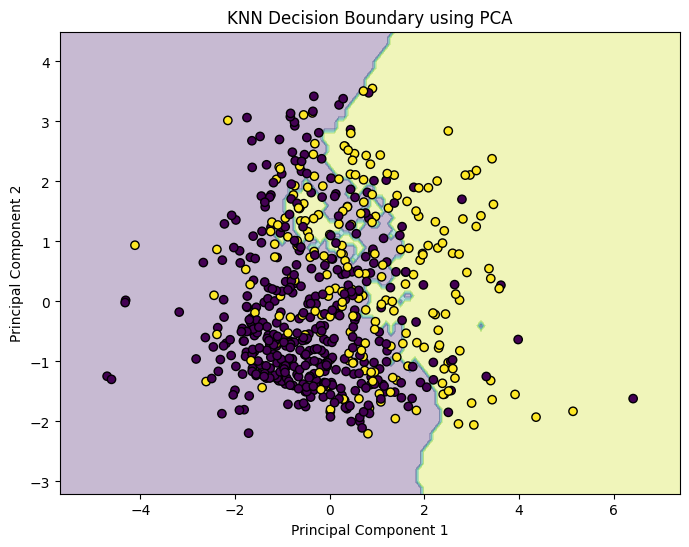

In [18]:
pca_model = KNeighborsClassifier(n_neighbors=best_k)
pca_model.fit(X_train_pca, y_train)

x_min, x_max = X_train_pca[:, 0].min() - 1, X_train_pca[:, 0].max() + 1
y_min, y_max = X_train_pca[:, 1].min() - 1, X_train_pca[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.arange(x_min, x_max, 0.1),
    np.arange(y_min, y_max, 0.1)
)

grid = np.c_[xx.ravel(), yy.ravel()]
Z = pca_model.predict(grid)
Z = Z.reshape(xx.shape)

plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, Z, alpha=0.3)
plt.scatter(
    X_train_pca[:, 0],
    X_train_pca[:, 1],
    c=y_train,
    edgecolors="black"
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("KNN Decision Boundary using PCA")
plt.show()

In [19]:
final_model = KNeighborsClassifier(n_neighbors=best_k)
final_model.fit(X_train_scaled, y_train)

print("Final KNN model trained with K =", best_k)

Final KNN model trained with K = 12


In [20]:
y_final_pred = final_model.predict(X_test_scaled)

print("Actual outcomes:", y_test.to_numpy()[:10])
print("Predicted outcomes:", y_final_pred[:10])

Actual outcomes: [0 0 0 1 0 0 1 1 0 0]
Predicted outcomes: [1 0 0 0 0 0 0 1 0 1]


In [21]:
final_accuracy = accuracy_score(y_test, y_final_pred)

print("Final Accuracy:", round(final_accuracy, 4))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_final_pred))

print("Classification Report:")
print(classification_report(y_test, y_final_pred))

Final Accuracy: 0.7727
Confusion Matrix:
[[88 12]
 [23 31]]
Classification Report:
              precision    recall  f1-score   support

           0       0.79      0.88      0.83       100
           1       0.72      0.57      0.64        54

    accuracy                           0.77       154
   macro avg       0.76      0.73      0.74       154
weighted avg       0.77      0.77      0.77       154



In [22]:
print("Selected K value:", best_k)
print("Final test accuracy:", round(final_accuracy, 4))

print("KNN classifies data using the nearest neighbors.")
print("Feature scaling helps prevent larger-valued features from dominating.")
print("The PCA plot shows a two-dimensional approximation of the class boundary.")

Selected K value: 12
Final test accuracy: 0.7727
KNN classifies data using the nearest neighbors.
Feature scaling helps prevent larger-valued features from dominating.
The PCA plot shows a two-dimensional approximation of the class boundary.
